In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from IPython.display import display

In [2]:
OUTPUT_DIR = Path("./eval_detection_subject12_new")

summary_csv = OUTPUT_DIR / "summary_per_activity.csv"
global_ap_csv = OUTPUT_DIR / "global_ap_by_iou.csv"
global_txt = OUTPUT_DIR / "global_results.txt"

activity_ap_files = sorted(
    [p for p in OUTPUT_DIR.glob("*_ap_by_iou.csv") if p.name != "global_ap_by_iou.csv"]
)

print("Fichiers trouvés :")
print(f"- summary_per_activity.csv : {summary_csv.exists()}")
print(f"- global_ap_by_iou.csv     : {global_ap_csv.exists()}")
print(f"- global_results.txt       : {global_txt.exists()}")
print(f"- nb fichiers AP activité  : {len(activity_ap_files)}")

Fichiers trouvés :
- summary_per_activity.csv : True
- global_ap_by_iou.csv     : True
- global_results.txt       : True
- nb fichiers AP activité  : 21


In [3]:
summary = pd.read_csv(summary_csv)
global_ap = pd.read_csv(global_ap_csv)

print("Aperçu du tableau summary :")
display(summary.head())

print("Aperçu du tableau global_ap :")
display(global_ap.head())

Aperçu du tableau summary :


,activity,n_images,n_gt,n_pred,tp,fp,fn,precision,recall,f1,mean_iou,ap50,map50_95
0,CMJump_01,168,252,249,247,2,5,0.991968,0.980159,0.986028,0.915955,0.980118,0.804509
1,CMJump_02,236,354,335,333,2,21,0.994030,0.940678,0.966618,0.905053,0.940475,0.745733
2,CMJump_03,264,488,469,468,1,20,0.997868,0.959016,0.978056,0.917378,0.950495,0.784298
3,Deadlift_01,200,300,298,295,3,5,0.989933,0.983333,0.986622,0.924122,0.979799,0.829823
4,Deadlift_02,472,708,701,699,2,9,0.997147,0.987288,0.992193,0.934466,0.980156,0.851013


Aperçu du tableau global_ap :


,iou,ap
0,0.50,0.940276
1,0.55,0.940133
2,0.60,0.940059
3,0.65,0.939844
4,0.70,0.938656


In [4]:
with open(global_txt, "r", encoding="utf-8") as f:
    print(f.read())

EVALUATION DETECTION
GT_ROOT: GT_detect_metasport12_new
VIDEOS_ROOT: \\intram\Paris\Labo\IBHGC\PROJETS\metasport\DATA\METASPORT12_undistort\Session1\Files\fichiers_video\Bruts\METASPORT12_undistorted
PRED_ROOT: results_1\videos_eval_new\ResultsMETASPORT12Rtmlib_V3
SCORE_THRESHOLD: None
OPERATING_IOU: 0.5

n_images: 8236
n_gt: 13813
n_pred: 13169
TP: 13069
FP: 100
FN: 744
Precision: 0.992406
Recall: 0.946138
F1: 0.968720
Mean IoU: 0.927380
AP50: 0.940276
mAP50-95: 0.798726



## 1. AP globale en fonction du seuil IoU

La courbe suivante montre l’évolution de l’Average Precision globale lorsque le seuil d’IoU devient plus exigeant.

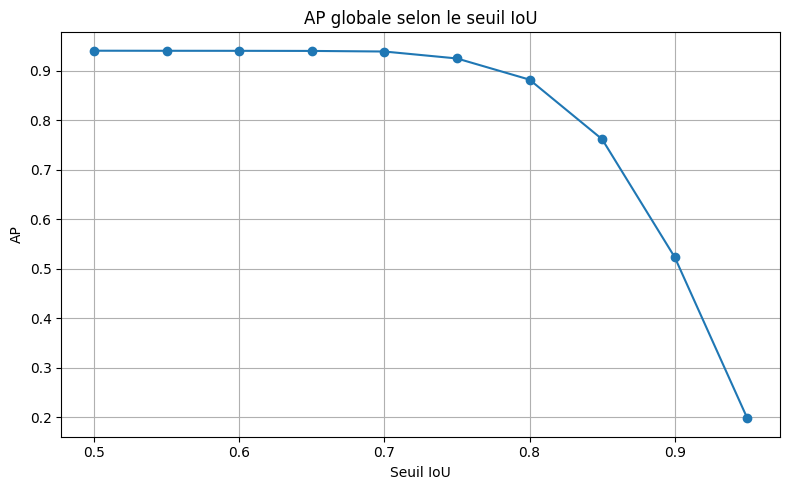

In [5]:
plt.figure(figsize=(8, 5))
plt.plot(global_ap["iou"], global_ap["ap"], marker="o")
plt.title("AP globale selon le seuil IoU")
plt.xlabel("Seuil IoU")
plt.ylabel("AP")
plt.grid(True)
plt.tight_layout()
plt.show()

La courbe montre que l’AP globale reste très élevée pour des seuils d’IoU compris entre 0.50 et 0.75. Cela indique que le modèle détecte globalement bien les personnes lorsque le critère de recouvrement entre la prédiction et la vérité terrain reste modéré.

À partir d’un seuil de 0.80, on observe une diminution plus marquée de l’AP.


## 2. Tableau récapitulatif par activité

Le tableau suivant regroupe l’ensemble des métriques calculées par le script pour chaque activité.

In [6]:
display(summary)

,activity,n_images,n_gt,n_pred,tp,fp,fn,precision,recall,f1,mean_iou,ap50,map50_95
0,CMJump_01,168,252,249,247,2,5,0.991968,0.980159,0.986028,0.915955,0.980118,0.804509
1,CMJump_02,236,354,335,333,2,21,0.994030,0.940678,0.966618,0.905053,0.940475,0.745733
2,CMJump_03,264,488,469,468,1,20,0.997868,0.959016,0.978056,0.917378,0.950495,0.784298
3,Deadlift_01,200,300,298,295,3,5,0.989933,0.983333,0.986622,0.924122,0.979799,0.829823
4,Deadlift_02,472,708,701,699,2,9,0.997147,0.987288,0.992193,0.934466,0.980156,0.851013
5,Deadlift_03,460,968,911,905,6,63,0.993414,0.934917,0.963278,0.919770,0.930528,0.774023
6,Deadlift_Polystyrene_01,232,348,342,341,1,7,0.997076,0.979885,0.988406,0.934609,0.970297,0.836058
7,Deadlift_Polystyrene_02,588,883,869,865,4,18,0.995397,0.979615,0.987443,0.935917,0.970146,0.843661
8,Deadlift_Polystyrene_03,428,880,842,824,18,56,0.978622,0.936364,0.957027,0.911228,0.927505,0.750638
9,EpauleDebout_01,268,386,383,380,3,6,0.992167,0.984456,0.988296,0.948602,0.979911,0.883606


In [7]:
summary_sorted_map = summary.sort_values("map50_95", ascending=False)
display(summary_sorted_map)

,activity,n_images,n_gt,n_pred,tp,fp,fn,precision,recall,f1,mean_iou,ap50,map50_95
16,SledPush_02,176,261,261,258,3,3,0.988506,0.988506,0.988506,0.951847,0.979930,0.907476
9,EpauleDebout_01,268,386,383,380,3,6,0.992167,0.984456,0.988296,0.948602,0.979911,0.883606
15,SledPush_01,360,524,517,505,12,19,0.976789,0.963740,0.970221,0.944984,0.959624,0.870511
10,EpauleDebout_02,636,929,904,900,4,29,0.995575,0.968784,0.981997,0.949564,0.960396,0.867397
11,EpauleDebout_03,596,1291,1279,1273,6,18,0.995309,0.986057,0.990661,0.937242,0.980104,0.861321
4,Deadlift_02,472,708,701,699,2,9,0.997147,0.987288,0.992193,0.934466,0.980156,0.851013
12,EpauleDebout_Polystyrene_01,240,331,329,329,0,2,1.000000,0.993958,0.996970,0.934427,0.990099,0.850127
7,Deadlift_Polystyrene_02,588,883,869,865,4,18,0.995397,0.979615,0.987443,0.935917,0.970146,0.843661
17,SledPush_03,128,240,237,234,3,6,0.987342,0.975000,0.981132,0.924804,0.970128,0.840090
13,EpauleDebout_Polystyrene_02,548,741,734,733,1,8,0.998638,0.989204,0.993898,0.927228,0.980185,0.838678


In [8]:
def plot_metric(metric, ylabel=None, figsize=(12, 5)):
    plt.figure(figsize=figsize)
    plt.bar(summary["activity"], summary[metric])
    plt.title(f"{metric} par activité")
    plt.ylabel(ylabel if ylabel else metric)
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

## 3. Précision par activité

La précision mesure la proportion de bonnes détections parmi l’ensemble des détections produites par le modèle.

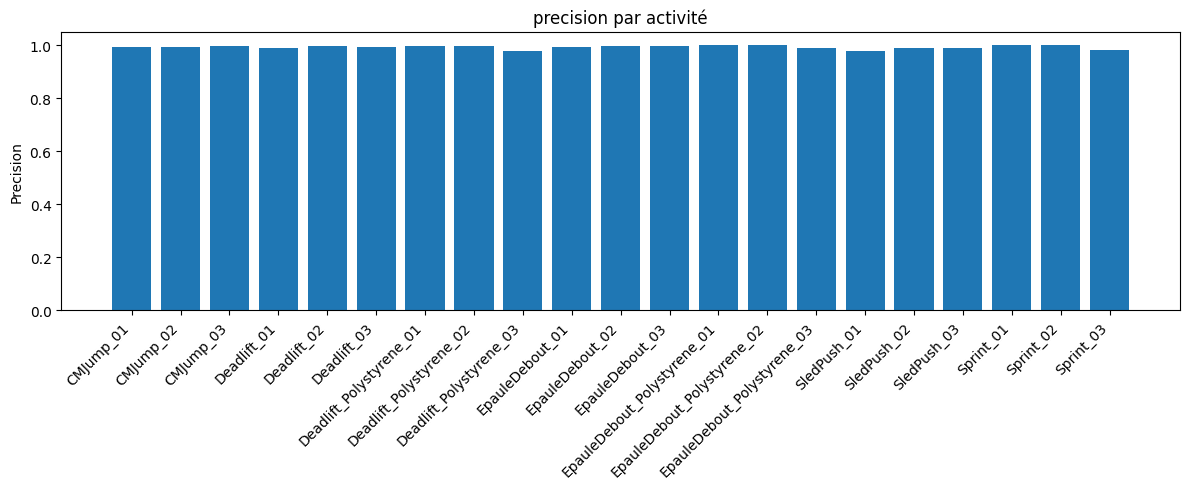

In [9]:
plot_metric("precision", ylabel="Precision")

La précision est élevée pour l’ensemble des activités, ce qui indique que le modèle génère peu de faux positifs. Donc, lorsqu’une personne est détectée, la prédiction est le plus souvent correcte.

## 4. Rappel par activité

Le rappel mesure la proportion d’objets réellement présents qui ont été détectés par le modèle.

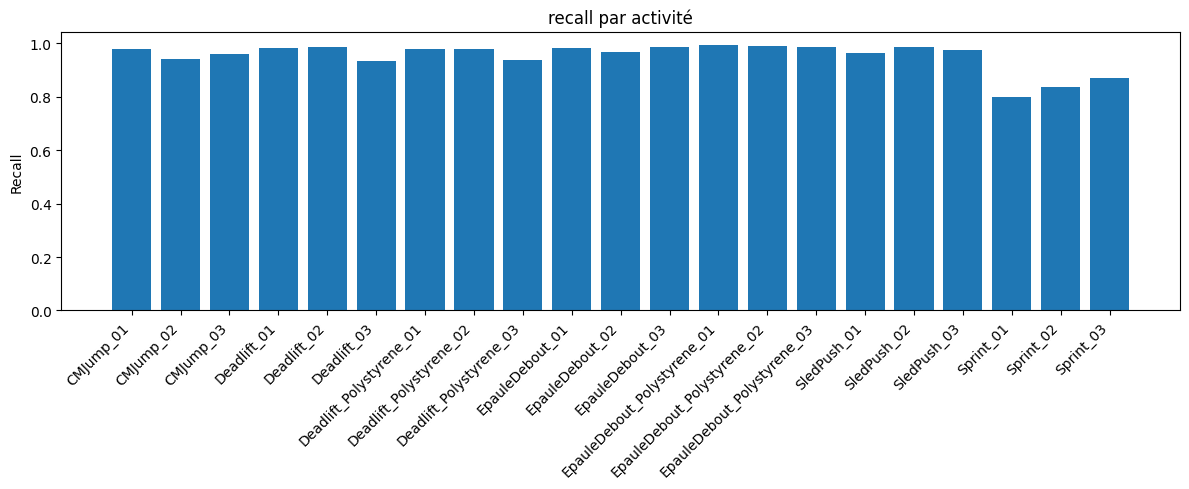

In [10]:
plot_metric("recall", ylabel="Recall")

Le rappel est également très élevé pour toutes les activités, ce qui montre que le modèle détecte la grande majorité des personnes présentes dans les images. Cela signifie qu’il génère peu de faux négatifs et qu’il manque rarement une détection.
tp/tp+fn élevé modèle oublie peu d'objets 

## 5. Score F1 par activité

Le score F1 permet de combiner la précision et le rappel en une seule mesure synthétique.

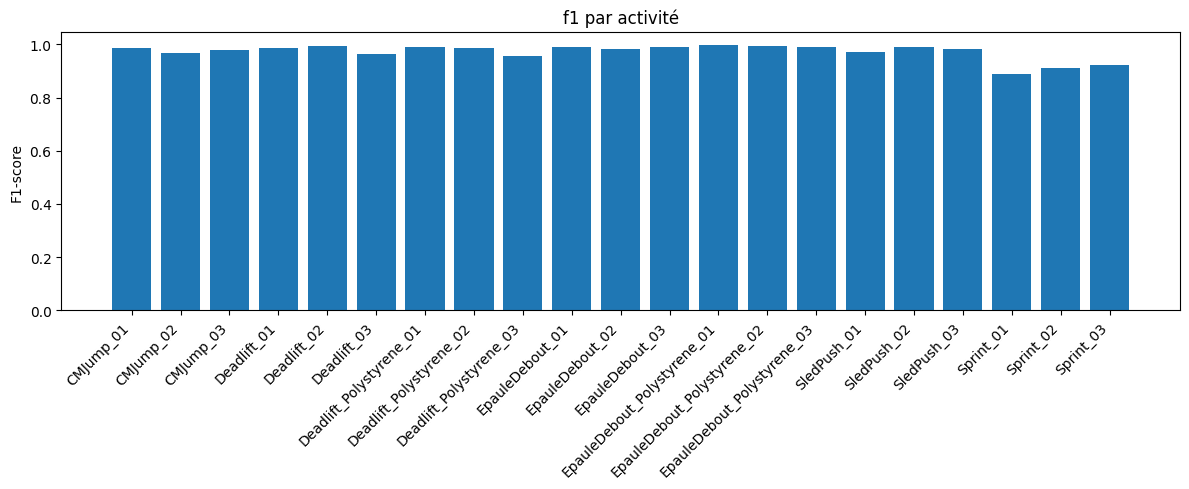

In [11]:
plot_metric("f1", ylabel="F1-score")

Le score F1 est élevé pour l’ensemble des activités donc un bon équilibre entre la précision et le rappel, le modèle détecte correctement la majorité des personnes présentes tout en générant peu de fausses détections.
f1=2* precision*rappel/precision+rappel

## 6. Mean IoU par activité

La Mean IoU donne une indication sur la qualité moyenne de localisation des boîtes correctement associées.

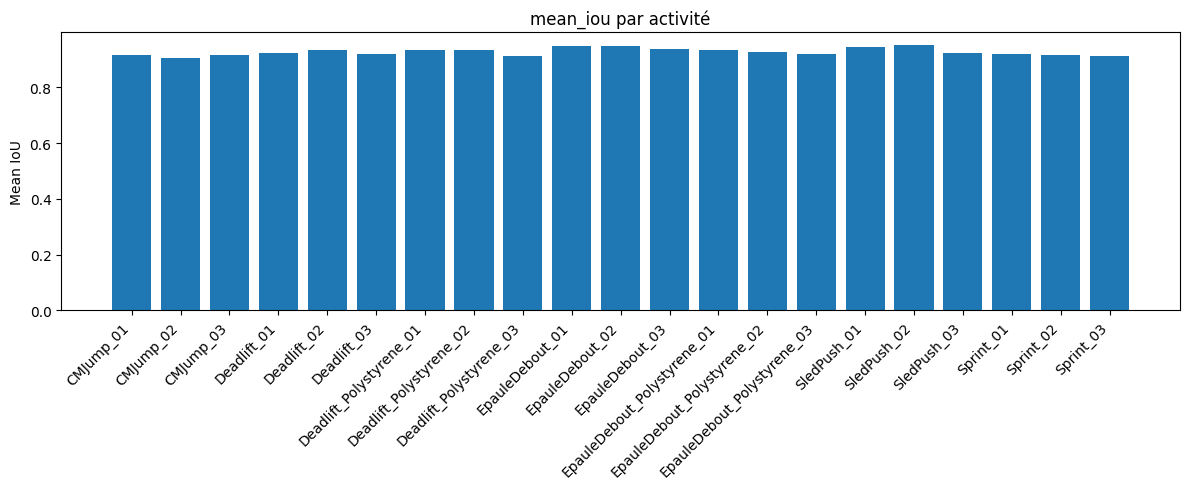

In [12]:
plot_metric("mean_iou", ylabel="Mean IoU")

(IoU: intersection over union): on compare bbox prédite avec GT et iou= intersection / union
La mean IoU est élevée ce qui indique que les boîtes prédites recouvrent globalement bien les annotations de GT.


## 7. AP50 par activité

L’AP50 mesure la qualité de détection pour un seuil d’IoU fixé à 0.50.

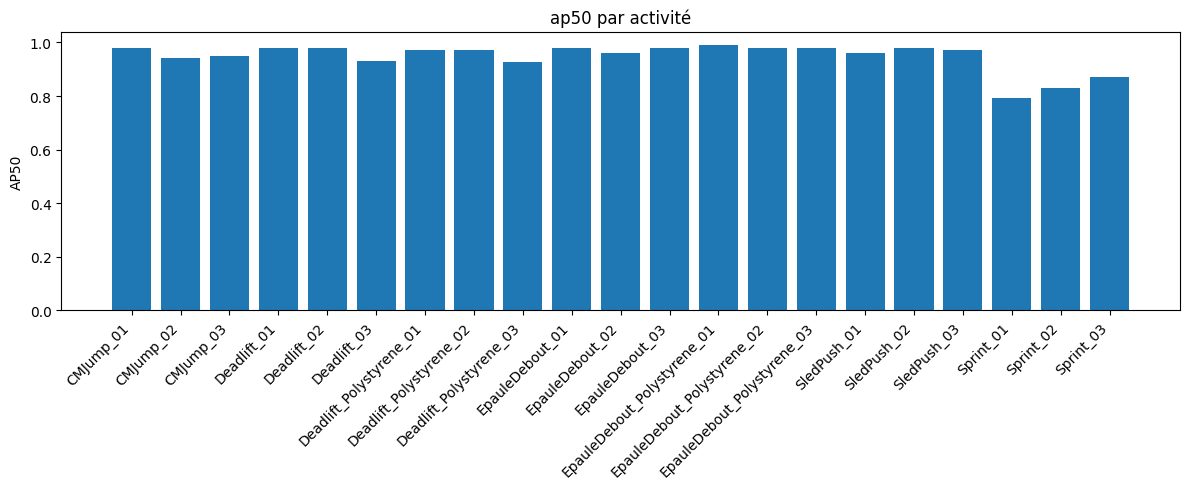

In [13]:
plot_metric("ap50", ylabel="AP50")

AP50: average precision avec seuil Iou =0.5
L’AP50 est élevée pour l’ensemble des activités, le modèle obtient de très bonnes performances de détection lorsque le critère de validation est fixé à un seuil d’IoU de 0.50, les personnes sont globalement bien détectées dans toutes les activités.

## 8. mAP50-95 par activité

Le mAP50-95 fournit une évaluation plus complète car il moyenne l’AP sur plusieurs seuils d’IoU.

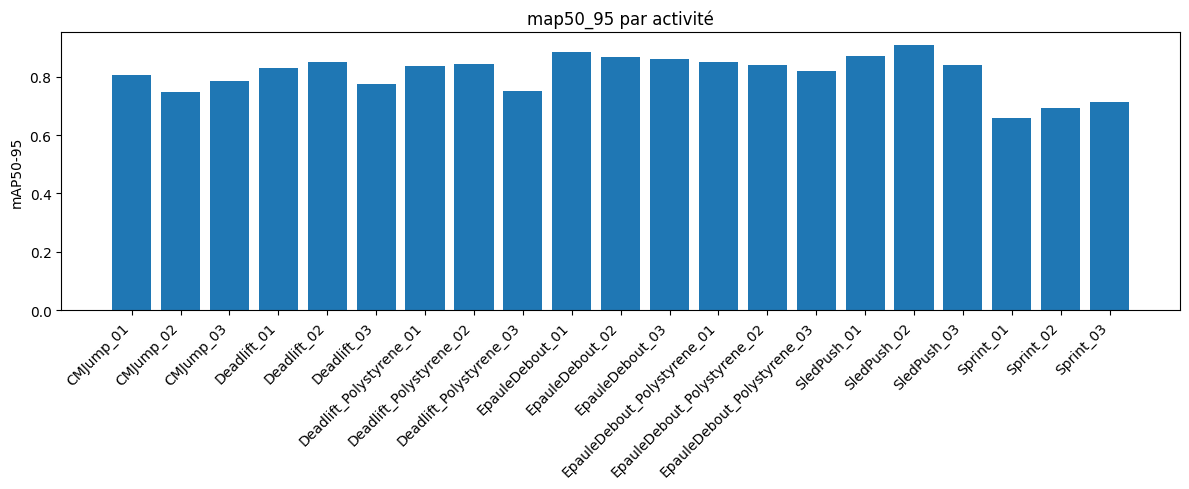

In [14]:
plot_metric("map50_95", ylabel="mAP50-95")

mAP50-95 : c'est la moyenne des AP calculée pour diff seuils de IoU de 0.5 à 0.95

## 9. TP, FP et FN par activité


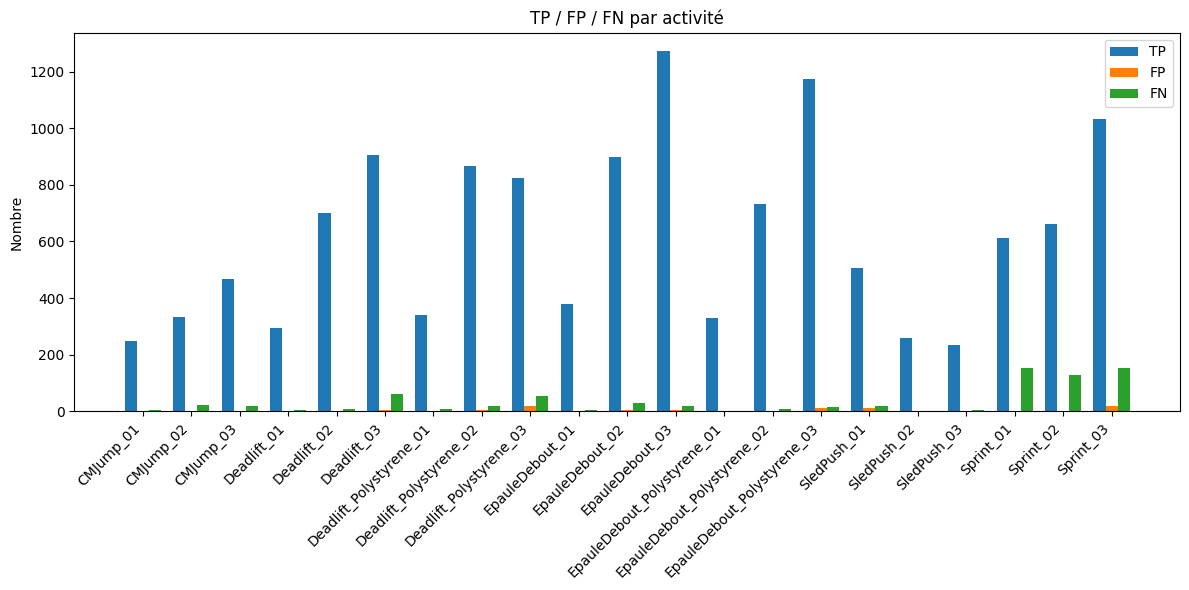

In [15]:
x = np.arange(len(summary["activity"]))
width = 0.25

plt.figure(figsize=(12, 6))

plt.bar(x - width, summary["tp"], width=width, label="TP")
plt.bar(x,         summary["fp"], width=width, label="FP")
plt.bar(x + width, summary["fn"], width=width, label="FN")

plt.title("TP / FP / FN par activité")
plt.ylabel("Nombre")
plt.xticks(x, summary["activity"], rotation=45, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

In [16]:
display(summary[["activity", "tp", "fp", "fn"]])

,activity,tp,fp,fn
0,CMJump_01,247,2,5
1,CMJump_02,333,2,21
2,CMJump_03,468,1,20
3,Deadlift_01,295,3,5
4,Deadlift_02,699,2,9
5,Deadlift_03,905,6,63
6,Deadlift_Polystyrene_01,341,1,7
7,Deadlift_Polystyrene_02,865,4,18
8,Deadlift_Polystyrene_03,824,18,56
9,EpauleDebout_01,380,3,6


## 10. Courbes AP selon le seuil IoU pour chaque activité


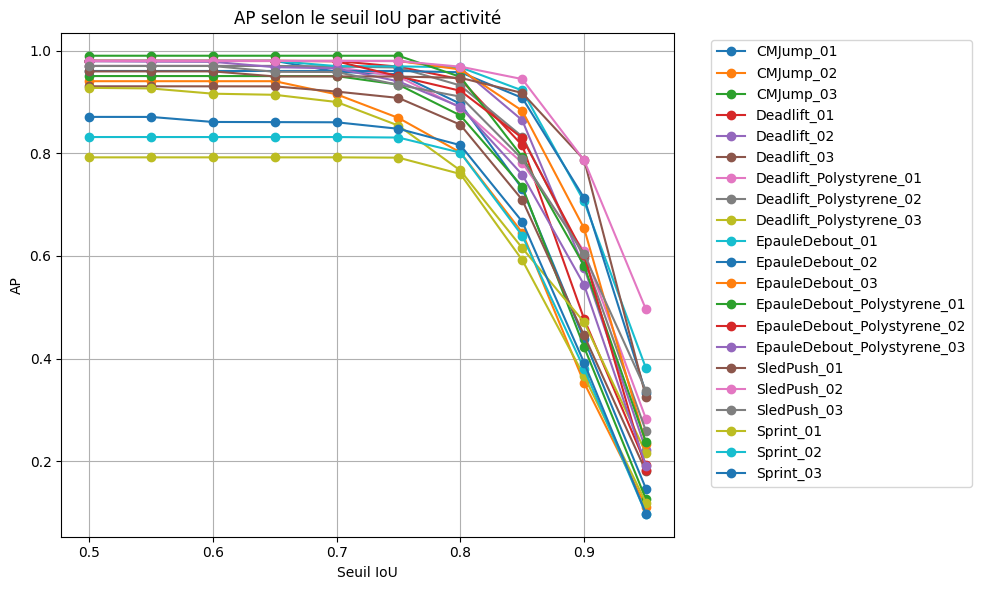

In [17]:
plt.figure(figsize=(10, 6))

for ap_file in activity_ap_files:
    ap_df = pd.read_csv(ap_file)
    activity_name = ap_file.name.replace("_ap_by_iou.csv", "")
    plt.plot(ap_df["iou"], ap_df["ap"], marker="o", label=activity_name)

plt.title("AP selon le seuil IoU par activité")
plt.xlabel("Seuil IoU")
plt.ylabel("AP")
plt.grid(True)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 14. Détail des valeurs AP par activité

Les tableaux suivants donnent les valeurs d’AP pour chaque activité et pour chaque seuil d’IoU.

In [18]:
for ap_file in activity_ap_files:
    activity_name = ap_file.name.replace("_ap_by_iou.csv", "")
    ap_df = pd.read_csv(ap_file)

    print("=" * 80)
    print(f"Activité : {activity_name}")
    display(ap_df)

Activité : CMJump_01


,iou,ap
0,0.50,0.980118
1,0.55,0.980118
2,0.60,0.980118
3,0.65,0.980118
4,0.70,0.958812
5,0.75,0.954117
6,0.80,0.896566
7,0.85,0.731076
8,0.90,0.437698
9,0.95,0.146350


Activité : CMJump_02


,iou,ap
0,0.50,0.940475
1,0.55,0.940475
2,0.60,0.940475
3,0.65,0.940475
4,0.70,0.914900
5,0.75,0.868839
6,0.80,0.801641
7,0.85,0.645548
8,0.90,0.352865
9,0.95,0.111638


Activité : CMJump_03


,iou,ap
0,0.50,0.950495
1,0.55,0.950495
2,0.60,0.950495
3,0.65,0.950410
4,0.70,0.950410
5,0.75,0.933753
6,0.80,0.873654
7,0.85,0.735145
8,0.90,0.422407
9,0.95,0.125713


... (32 outputs left out)

Activité : Sprint_02


,iou,ap
0,0.50,0.831683
1,0.55,0.831683
2,0.60,0.831653
3,0.65,0.831653
4,0.70,0.831653
5,0.75,0.830676
6,0.80,0.801297
7,0.85,0.639447
8,0.90,0.380226
9,0.95,0.097413


Activité : Sprint_03


,iou,ap
0,0.50,0.870912
1,0.55,0.870842
2,0.60,0.861040
3,0.65,0.860759
4,0.70,0.860410
5,0.75,0.847735
6,0.80,0.815840
7,0.85,0.666941
8,0.90,0.392001
9,0.95,0.097540
